Introduction: In this project, I am analyzing a dataset of telecom customers to understand "churn", which means figuring out why customers decide to cancel their service.

In [2]:
import pandas as pd

df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [6]:
#convert Yes/No to 1/0
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})
df['Churn'].head() #to verify

0   NaN
1   NaN
2   NaN
3   NaN
4   NaN
Name: Churn, dtype: float64

In [7]:
#display current datatypes
print(df.dtypes)

#change TotalCharges to numeric, forcing errors(blanks) to become NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn               float64
dtype: object


In [8]:
#display the count of null values per column
print(df.isnull().sum())

#remove rows with null values permanently
df.dropna(inplace=True)

#verify they are gone
print("\nAfter removal:")
print(df.isnull().sum())

customerID             0
gender                 0
SeniorCitizen          0
Partner                0
Dependents             0
tenure                 0
PhoneService           0
MultipleLines          0
InternetService        0
OnlineSecurity         0
OnlineBackup           0
DeviceProtection       0
TechSupport            0
StreamingTV            0
StreamingMovies        0
Contract               0
PaperlessBilling       0
PaymentMethod          0
MonthlyCharges         0
TotalCharges          11
Churn               7043
dtype: int64

After removal:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn 

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

#set a clean style for our charts
sns.set_theme(style="whitegrid")

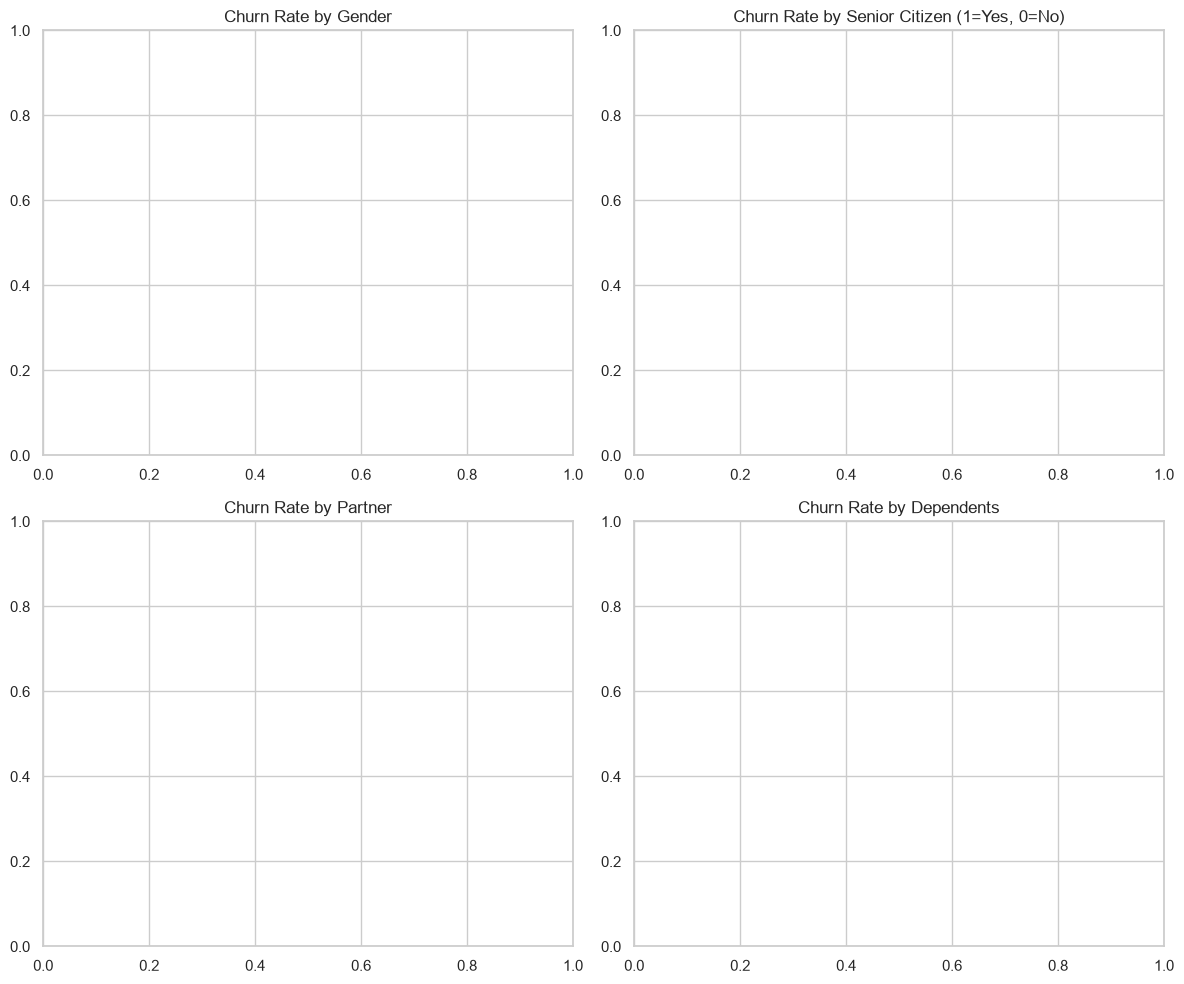

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

#plotting Churn rates for demographics
sns.barplot(x='gender', y='Churn', data=df, ax=axes[0,0], errorbar=None)
axes[0,0].set_title('Churn Rate by Gender')

sns.barplot(x='SeniorCitizen', y='Churn', data=df, ax=axes[0,1], errorbar=None)
axes[0,1].set_title('Churn Rate by Senior Citizen (1=Yes, 0=No)')

sns.barplot(x='Partner', y='Churn', data=df, ax=axes[1,0], errorbar=None)
axes[1,0].set_title('Churn Rate by Partner')

sns.barplot(x='Dependents', y='Churn', data=df, ax=axes[1,1], errorbar=None)
axes[1,1].set_title('Churn Rate by Dependents')

plt.tight_layout()
plt.show()

Demographic Insights(in Above charts):

Gender: Male and female customers churn at almost the exact same rate (~26%), meaning gender is not a strong indicator of churn.

Senior Citizen: Senior citizens have a significantly higher churn rate (~41%) compared to younger customers (~23%).

Partner & Dependents: Customers without partners or dependents are nearly twice as likely to churn compared to those with families. Family households are more stable customers.

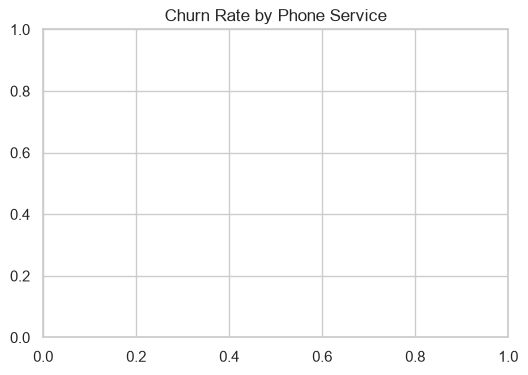

In [14]:
plt.figure(figsize=(6, 4))
sns.barplot(x='PhoneService', y='Churn', data=df, errorbar=None)
plt.title('Churn Rate by Phone Service')
plt.show()

Service Insights(Above):

Phone Service: Customers with phone service and those without phone service churn at very similar rates (~26% vs ~25%). Simply having a phone line does not heavily influence whether a customer will leave.

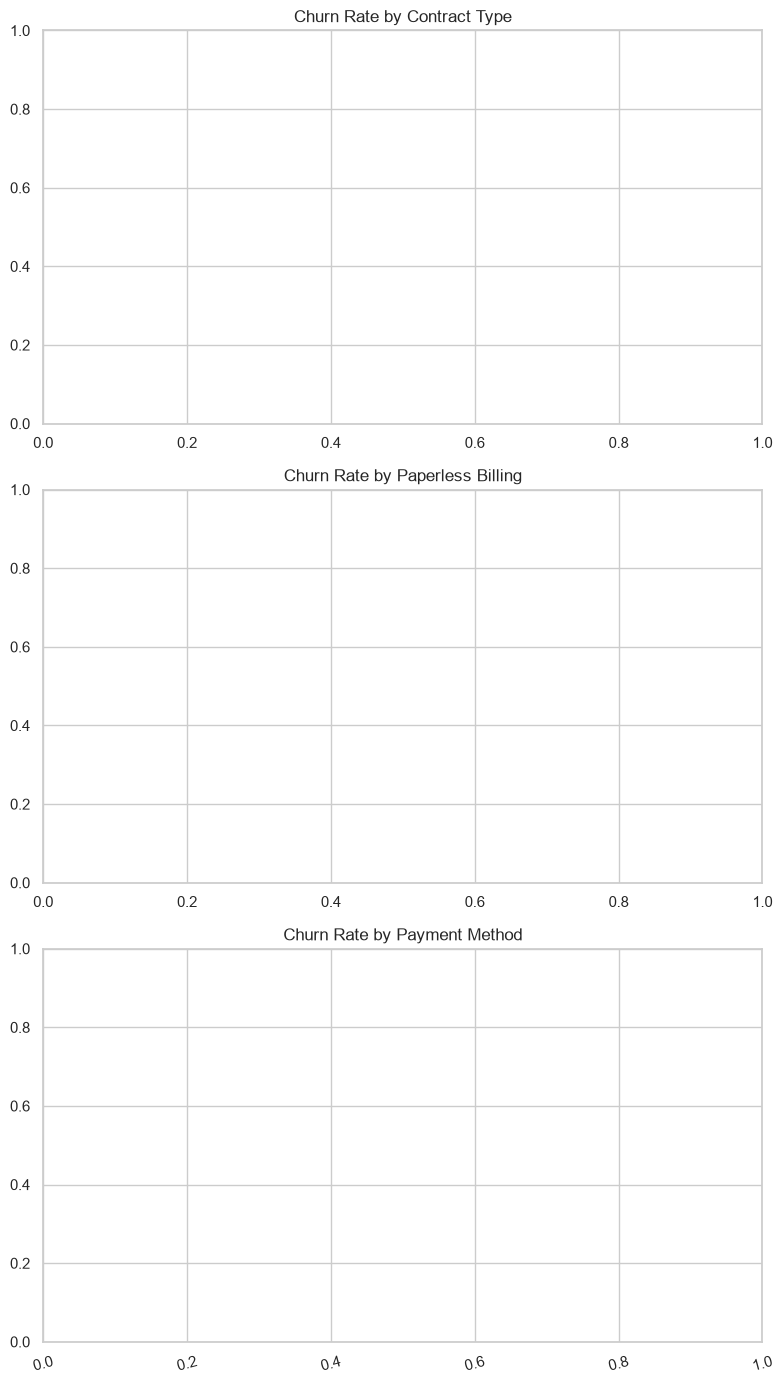

In [15]:
fig, axes = plt.subplots(3, 1, figsize=(8, 14))

sns.barplot(x='Contract', y='Churn', data=df, ax=axes[0], errorbar=None)
axes[0].set_title('Churn Rate by Contract Type')

sns.barplot(x='PaperlessBilling', y='Churn', data=df, ax=axes[1], errorbar=None)
axes[1].set_title('Churn Rate by Paperless Billing')

sns.barplot(x='PaymentMethod', y='Churn', data=df, ax=axes[2], errorbar=None)
axes[2].set_title('Churn Rate by Payment Method')
plt.xticks(rotation=15) # Rotate labels so they don't overlap

plt.tight_layout()
plt.show()

Payments Insights(Above):

Contract: Month-to-month contracts have a massively higher churn rate (~42%) compared to one-year (~11%) or two-year contracts (~2%). Customers locked into longer contracts rarely leave.

Paperless Billing: Customers using paperless billing churn at a higher rate (~33%) than those receiving paper bills (~16%).

Payment Method: Customers paying by "Electronic check" are highly likely to churn (~45%) compared to those using automatic bank transfers or credit cards (~15-16%).